<a href="https://colab.research.google.com/github/Littlederik/pi/blob/main/torch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
from torch import nn
import matplotlib.pyplot as plt

In [17]:
weight=0.7
bias=0.2

start=0
end=1
step=0.02
x=torch.arange(start,end,step).unsqueeze(dim=1)
print(x.shape)
y=weight*x +bias
print(x)

torch.Size([50, 1])
tensor([[0.0000],
        [0.0200],
        [0.0400],
        [0.0600],
        [0.0800],
        [0.1000],
        [0.1200],
        [0.1400],
        [0.1600],
        [0.1800],
        [0.2000],
        [0.2200],
        [0.2400],
        [0.2600],
        [0.2800],
        [0.3000],
        [0.3200],
        [0.3400],
        [0.3600],
        [0.3800],
        [0.4000],
        [0.4200],
        [0.4400],
        [0.4600],
        [0.4800],
        [0.5000],
        [0.5200],
        [0.5400],
        [0.5600],
        [0.5800],
        [0.6000],
        [0.6200],
        [0.6400],
        [0.6600],
        [0.6800],
        [0.7000],
        [0.7200],
        [0.7400],
        [0.7600],
        [0.7800],
        [0.8000],
        [0.8200],
        [0.8400],
        [0.8600],
        [0.8800],
        [0.9000],
        [0.9200],
        [0.9400],
        [0.9600],
        [0.9800]])


In [15]:
train_split=int(0.8*len(x))
x_train,y_train=x[:train_split],y[:train_split]
x_test,y_test=x[train_split:],y[train_split:]
print(len(x_train),len(x_test),len(y_train),len(y_test))

40 10 40 10


In [18]:
def plot_prediction(train_data=x_train,train_label=y_train,test_data=x_test,test_label=y_test,predictions=None):
  plt.figure(figsize=(10,7))
  plt.scatter(train_data,train_label,c="b",s=4,label="Training data")
  plt.scatter(test_data,test_label,c="g",s=4,label="testing data")

  if predictions is not None:
    plt.scatter(test_data,predictions,c="r",s=4,label="predictions")
  plt.legend(prop={"size":14})

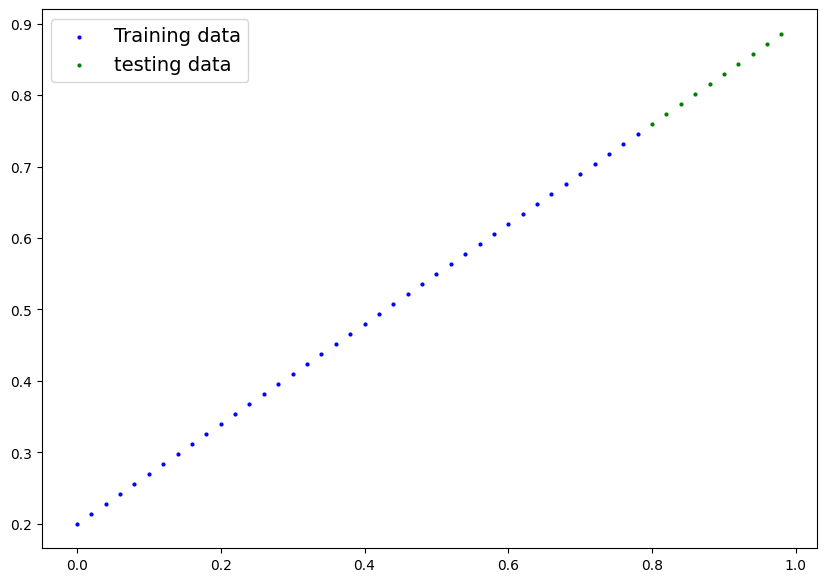

In [19]:
plot_prediction()

In [21]:
class linearregressionmodel(nn.Module):
  def __init__(self):
    super().__init__()
    self.weights=nn.Parameter(torch.randn(1,dtype=torch.float),requires_grad=True)
    self.bias=nn.Parameter(torch.randn(1,dtype=torch.float),requires_grad=True)

  def forward(self,x:torch.Tensor) -> torch.Tensor:
    return self.weights * x +self.bias

In [22]:
torch.manual_seed(42)
model_0=linearregressionmodel()
list(model_0.parameters())

[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

In [23]:
# List named parameters
model_0.state_dict()

OrderedDict([('weights', tensor([0.3367])), ('bias', tensor([0.1288]))])

In [24]:
loss_fn=nn.L1Loss()

optimizer=torch.optim.SGD(params=model_0.parameters(),lr=0.01)

In [30]:
epochs=200
train_loss_values=[]
test_loss_values=[]
epoch_count=[]

for epoch in range(epochs):
  model_0.train
  y_pred=model_0(x_train)
  loss=loss_fn(y_pred,y_train)
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()

  model_0.eval()

  with torch.inference_mode():
    test_pred=model_0(x_test)
    test_loss=loss_fn(test_pred,y_test.type(torch.float))

    if epoch %10==0:
      epoch_count.append(epoch)
      train_loss_values.append(loss.detach().numpy())
      test_loss_values.append(test_loss.detach().numpy())

      print(f"Epoch: {epoch} | MAE train loss: {loss} | MAE test loss: {test_loss}")


Epoch: 0 | MAE train loss: 0.027962392196059227 | MAE test loss: 0.06443102657794952
Epoch: 10 | MAE train loss: 0.02452731318771839 | MAE test loss: 0.05684535577893257
Epoch: 20 | MAE train loss: 0.0210975781083107 | MAE test loss: 0.04857286810874939
Epoch: 30 | MAE train loss: 0.017658770084381104 | MAE test loss: 0.040300387889146805
Epoch: 40 | MAE train loss: 0.014225363731384277 | MAE test loss: 0.03271481394767761
Epoch: 50 | MAE train loss: 0.010793947614729404 | MAE test loss: 0.024442333728075027
Epoch: 60 | MAE train loss: 0.007355140056461096 | MAE test loss: 0.016169846057891846
Epoch: 70 | MAE train loss: 0.003923413809388876 | MAE test loss: 0.00858424324542284
Epoch: 80 | MAE train loss: 0.004262552596628666 | MAE test loss: 0.005269003100693226
Epoch: 90 | MAE train loss: 0.004262552596628666 | MAE test loss: 0.005269003100693226


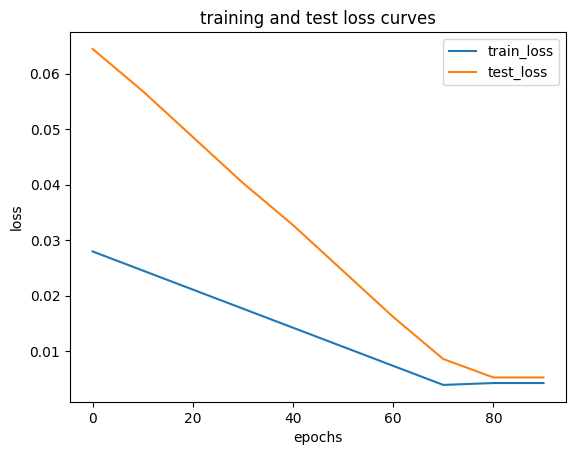

In [31]:
plt.plot(epoch_count,train_loss_values,label="train_loss")
plt.plot(epoch_count,test_loss_values,label="test_loss")
plt.title("training and test loss curves")
plt.xlabel("epochs")
plt.ylabel("loss")
plt.legend();

In [32]:
# Find our model's learned parameters
print("The model learned the following values for weights and bias:")
print(model_0.state_dict())
print("\nAnd the original values for weights and bias are:")
print(f"weights: {weight}, bias: {bias}")

The model learned the following values for weights and bias:
OrderedDict({'weights': tensor([0.6921]), 'bias': tensor([0.1988])})

And the original values for weights and bias are:
weights: 0.7, bias: 0.2


In [33]:
# 1. Set the model in evaluation mode
model_0.eval()

# 2. Setup the inference mode context manager
with torch.inference_mode():
  # 3. Make sure the calculations are done with the model and data on the same device
  # in our case, we haven't setup device-agnostic code yet so our data and model are
  # on the CPU by default.
  # model_0.to(device)
  # X_test = X_test.to(device)
  y_preds = model_0(x_test)
y_preds

tensor([[0.7525],
        [0.7663],
        [0.7802],
        [0.7940],
        [0.8079],
        [0.8217],
        [0.8356],
        [0.8494],
        [0.8632],
        [0.8771]])

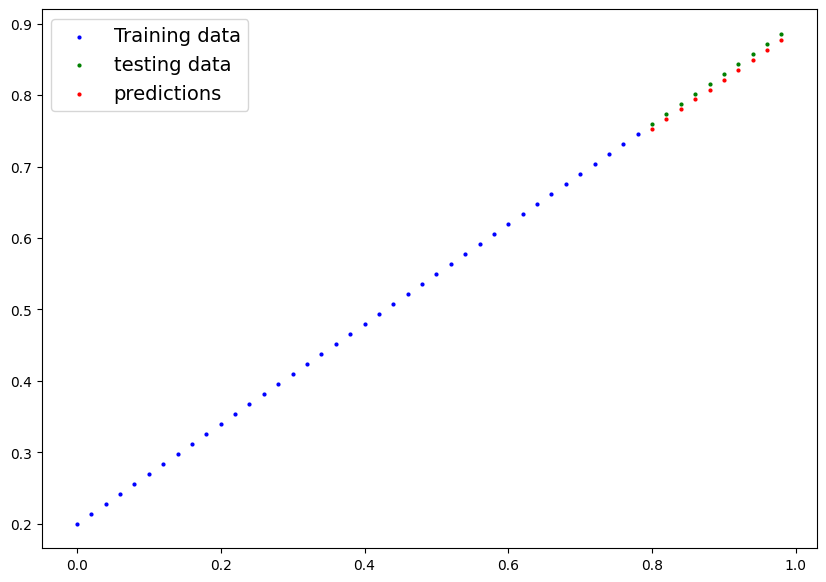

In [35]:
plot_prediction(predictions=y_preds)

In [36]:
from pathlib import Path

# 1. Create models directory
MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)

# 2. Create model save path
MODEL_NAME = "01_pytorch_workflow_model_0.pth"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME

# 3. Save the model state dict
print(f"Saving model to: {MODEL_SAVE_PATH}")
torch.save(obj=model_0.state_dict(), # only saving the state_dict() only saves the models learned parameters
           f=MODEL_SAVE_PATH)

Saving model to: models/01_pytorch_workflow_model_0.pth


In [37]:
# Check the saved file path
!ls -l models/01_pytorch_workflow_model_0.pth

-rw-r--r-- 1 root root 2117 Oct 28 16:36 models/01_pytorch_workflow_model_0.pth


In [39]:
# Instantiate a new instance of our model (this will be instantiated with random weights)
loaded_model_0 = linearregressionmodel()

# Load the state_dict of our saved model (this will update the new instance of our model with trained weights)
loaded_model_0.load_state_dict(torch.load(f=MODEL_SAVE_PATH))

<All keys matched successfully>

In [41]:
# 1. Put the loaded model into evaluation mode
loaded_model_0.eval()

# 2. Use the inference mode context manager to make predictions
with torch.inference_mode():
    loaded_model_preds = loaded_model_0(x_test) # perform a forward pass on the test data with the loaded model

In [42]:
# Compare previous model predictions with loaded model predictions (these should be the same)
y_preds == loaded_model_preds

tensor([[True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True]])